# Punto de equilibrio del cobro de matrícula: créditos vs. bandas

**Pregunta.** ¿Con qué parámetros cada método de cobro deja el ingreso de la universidad **igual al actual** (394,56 mil millones, 2021-1 a 2026-1)? ¿Qué tan robusto es ese punto si los estudiantes reaccionan al precio o si cambia el periodo?

| Método | Cómo cobra | Ingreso tal como se presentó |
|---|---|---|
| **Créditos** (`Proyecto_u.R`) | créditos × tarifa plena por crédito T × (1 − beca) | 353,90 (−10,30 %) |
| **Bandas** (`metodo_bandas/`) | 1–6 y 7–11 pagan una fracción de M proporcional a su carga en cada facultad; 12–18 paga M; 19+ paga M + T por crédito extra | 386,14 (−2,13 %) |

Este cuaderno es el análisis; el mismo simulador está publicado como API (`backend/`, FastAPI) y tablero (`frontend/`, Streamlit).

| Módulo del curso | Dónde se usa en el proyecto |
|---|---|
| 1. Python para APIs e IA | type hints, decoradores propios (`@medir_tiempo`), entorno virtual, Git |
| 2. HTTP | API REST con verbos y códigos correctos (200, 201, 204, 400, 404, 422, 503) |
| 3. POO y clases | `MetodoCobro` (clase abstracta), `CobroPorCreditos`, `CobroPorBandas`, `Simulador`, `ModelStore`, `ModelPredictor` |
| 4 y 7. Pydantic y validación | rangos de cada palanca, unión discriminada por `metodo`, validadores de periodos y de palancas |
| 5 y 6. Del modelo al servicio, FastAPI | routers `/simulaciones`, `/equilibrio`, `/montecarlo`, `/validacion-temporal`, `/predict`; `/docs` y `/redoc` |
| 8. Inyección de dependencias | `Depends(get_settings)`, `get_db`, `get_simulador`, `get_predictor`; `BaseSettings` + `.env` |
| 9. SQLAlchemy | historial de simulaciones y log de predicciones en SQLite |
| 10. Testing | 32 pruebas con pytest + TestClient y BD en memoria |
| 11 y 12. Docker, PaaS y CI/CD | Dockerfile multi-stage, docker-compose, `render.yaml`, GitHub Actions |
| 13. ML en producción | metamodelo entrenado offline, `joblib`, Singleton con cerrojo, `/predict` |
| Análisis | pandas, numpy, scipy (`brentq`), scikit-learn, matplotlib, seaborn |

**Privacidad.** El simulador trabaja con una base agregada por facultad × periodo × banda (308 celdas, mínimo 7 estudiantes cada una) que reproduce exactamente los totales fila a fila. Las secciones 8 y 9 usan la base de estudiantes solo si está disponible en local, y solo muestran agregados.

## 1. Preparación

In [1]:
import sys, warnings, json
from pathlib import Path
warnings.filterwarnings("ignore")

RAIZ = Path.cwd().parent                     # simulacion_ml/
sys.path.insert(0, str(RAIZ / "backend"))
sys.path.insert(0, str(RAIZ / "scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from app.services.datos import cargar_base_agregada
from app.services.simulador import Simulador, fracciones_proporcionales
from app.ml.predictor import ModelStore, ModelPredictor

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
RESULTADOS, GRAFICAS = RAIZ / "resultados", RAIZ / "graficas"
RESULTADOS.mkdir(exist_ok=True); GRAFICAS.mkdir(exist_ok=True)

def guardar(tabla, nombre, **kw):
    tabla.to_csv(RESULTADOS / nombre, sep=";", decimal=",", **kw)

celdas = cargar_base_agregada(RAIZ / "backend/app/data/base_agregada.csv")
sim = Simulador(celdas)
METODOS = {"creditos": "Créditos", "bandas": "Bandas"}
PALANCA_PRINCIPAL = {"creditos": "factor_tarifa", "bandas": "k_parcial"}
print(f"Celdas: {len(celdas)} | estudiantes-periodo: {celdas.N.sum():,} | mínimo por celda: {celdas.N.min()}")

Celdas: 308 | estudiantes-periodo: 77,476 | mínimo por celda: 7


In [2]:
# Base de estudiantes (opcional): solo para las secciones 8 y 9
try:
    from preparar_agregados import buscar_base, preparar_base
    import os
    estudiantes = preparar_base(Path(os.environ["RUTA_DATOS"])) if os.environ.get("RUTA_DATOS") else None
except SystemExit:
    estudiantes = None
print("Base de estudiantes disponible" if estudiantes is not None else "Sin base de estudiantes: se omiten las secciones 8 y 9")

Base de estudiantes disponible


## 2. Cuadre con lo ya presentado

In [3]:
cuadre = pd.DataFrame([
    {"Metodo": METODOS[m], "Ingreso_real_MM": r.ingreso_real / 1e9,
     "Ingreso_simulado_MM": r.ingreso_simulado / 1e9, "Brecha_MM": r.brecha / 1e9, "Brecha_pct": r.brecha_pct}
    for m in METODOS for r in [sim.simular(m)]])
guardar(cuadre.round(4), "cuadre_con_R.csv", index=False)
cuadre.round(2)

,Metodo,Ingreso_real_MM,Ingreso_simulado_MM,Brecha_MM,Brecha_pct
0,Créditos,394.56,353.90,-40.66,-10.30
1,Bandas,394.56,386.14,-8.42,-2.13


## 3. ¿Dónde se pierde ingreso hoy con cada método?

In [4]:
por_banda = pd.concat({METODOS[m]: sim.simular_por("BANDA", m).set_index("BANDA") for m in METODOS}, axis=1)
tabla = pd.DataFrame({
    "Estudiantes": por_banda[("Créditos", "N")],
    "Real_MM": por_banda[("Créditos", "INGRESO_REAL")] / 1e9,
    "Creditos_MM": por_banda[("Créditos", "SIMULADO")] / 1e9,
    "Bandas_MM": por_banda[("Bandas", "SIMULADO")] / 1e9,
}).loc[["1-6", "7-11", "12-18", "19+"]]
tabla["Brecha_creditos_MM"] = tabla.Creditos_MM - tabla.Real_MM
tabla["Brecha_bandas_MM"] = tabla.Bandas_MM - tabla.Real_MM
tabla.round(2)

,Estudiantes,Real_MM,Creditos_MM,Bandas_MM,Brecha_creditos_MM,Brecha_bandas_MM
BANDA,,,,,,
1-6,4621,7.32,2.01,5.63,-5.31,-1.69
7-11,8614,27.03,14.81,24.62,-12.22,-2.42
12-18,54614,302.04,274.21,293.92,-27.82,-8.12
19+,9627,58.17,62.87,61.97,4.70,3.80


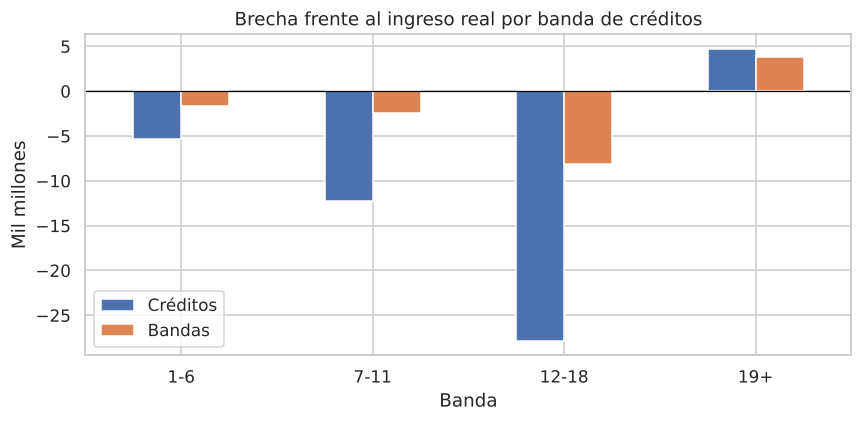

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
tabla[["Brecha_creditos_MM", "Brecha_bandas_MM"]].rename(
    columns={"Brecha_creditos_MM": "Créditos", "Brecha_bandas_MM": "Bandas"}).plot.bar(ax=ax, rot=0)
ax.axhline(0, c="black", lw=0.8)
ax.set(title="Brecha frente al ingreso real por banda de créditos", xlabel="Banda", ylabel="Mil millones")
plt.tight_layout(); plt.savefig(GRAFICAS / "01_brecha_por_banda.png", bbox_inches="tight"); plt.show()

## 4. Punto de equilibrio exacto

Para cada método se mueve **una palanca a la vez** y `scipy.optimize.brentq` encuentra el valor que deja la brecha en cero.

- **Créditos:** `factor_tarifa` multiplica la tarifa por crédito.
- **Bandas:** `k_parcial` multiplica las fracciones de 1–6 y 7–11; `ajuste_plena` multiplica la matrícula plena M; `tarifa_extra` multiplica el cobro por crédito sobre 18.

La `elasticidad` es un supuesto de sensibilidad (la base no permite estimarla): en créditos, si la tarifa sube x %, cada estudiante inscribe e·x % menos créditos; en bandas, quien inscribe 12–13 créditos baja a 11 con probabilidad e·(1 − F2), y quien inscribe 19–20 baja a 18 con probabilidad e·(cobro extra / M).

In [6]:
filas = []
for m in METODOS:
    for p in sim.metodo(m).palancas:
        if p.nombre == "elasticidad":
            continue
        try:
            valor = sim.equilibrio(m, p.nombre)
        except ValueError:
            valor = np.nan
        filas.append({"Metodo": METODOS[m], "Palanca": p.nombre, "Descripcion": p.descripcion,
                      "Valor_equilibrio": valor, "Cambio_pct": (valor - p.actual) * 100})
equilibrios = pd.DataFrame(filas)
guardar(equilibrios.round(6), "equilibrio_por_palanca.csv", index=False)
equilibrios.round(4)

,Metodo,Palanca,Descripcion,Valor_equilibrio,Cambio_pct
0,Créditos,factor_tarifa,Multiplica la tarifa plena por crédito T,1.1149,11.4888
1,Bandas,k_parcial,Multiplica las fracciones de 1-6 y 7-11 (tope 1),1.2784,27.8385
2,Bandas,ajuste_plena,Multiplica la matrícula plena M en todas las b...,1.0221,2.2143
3,Bandas,tarifa_extra,Multiplica T en el cobro por crédito sobre 18,2.4521,145.2063


In [7]:
eq_cred = sim.equilibrio("creditos", "factor_tarifa")
eq_band = sim.equilibrio("bandas", "k_parcial")
fr = fracciones_proporcionales(celdas)
fr["F1_equilibrio"] = (fr.F1 * eq_band).clip(upper=1)
fr["F2_equilibrio"] = (fr.F2 * eq_band).clip(upper=1)
guardar(fr.round(4), "fracciones_equilibrio_por_facultad.csv", index=False)
print(f"Créditos: tarifa por crédito × {eq_cred:.4f} (+{(eq_cred - 1) * 100:.2f} %)")
print(f"Bandas:   fracciones × {eq_band:.4f} → en promedio {fr.F1_equilibrio.mean():.3f} (1–6) y {fr.F2_equilibrio.mean():.3f} (7–11) de M")
fr.round(3)

Créditos: tarifa por crédito × 1.1149 (+11.49 %)
Bandas:   fracciones × 1.2784 → en promedio 0.321 (1–6) y 0.747 (7–11) de M


,FACULTAD,F1,F2,F1_equilibrio,F2_equilibrio
0,CIENCIAS DE LA COMUNICACIÓN Y LA CREACIÓN,0.248,0.578,0.317,0.739
1,CIENCIAS DE LA SALUD,0.257,0.600,0.328,0.767
2,CIENCIAS ECONÓMICAS Y ADMINISTRATIVAS,0.273,0.578,0.349,0.739
3,CIENCIAS JURÍDICAS Y POLÍTICAS,0.237,0.552,0.302,0.705
4,CIENCIAS SOCIALES Y DE LA EDUCACIÓN,0.260,0.593,0.332,0.758
5,FILOSOFÍA Y TEOLOGÍA,0.232,0.612,0.296,0.782
6,INGENIERÍAS,0.250,0.577,0.320,0.738


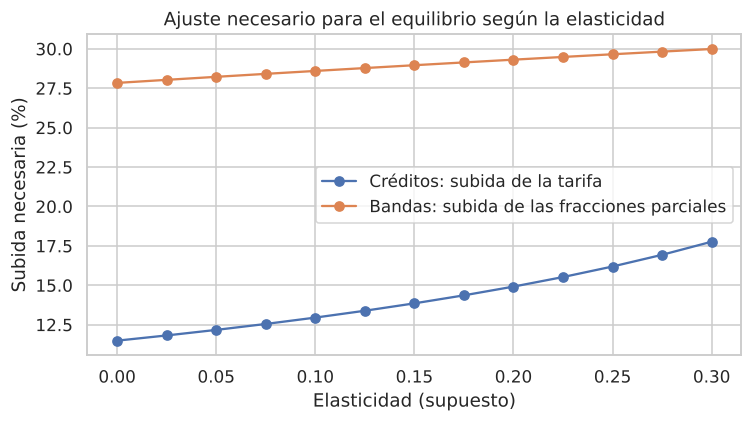

,elasticidad,Créditos,Bandas,Créditos (% de subida),Bandas (% de subida de k)
0,0.000,1.1149,1.2784,11.4888,27.8385
1,0.025,1.1182,1.2803,11.8193,28.0326
2,0.050,1.1217,1.2822,12.1715,28.2238
3,0.075,1.1255,1.2841,12.5480,28.4120
4,0.100,1.1295,1.2860,12.9518,28.5975
5,0.125,1.1339,1.2878,13.3861,28.7802
6,0.150,1.1386,1.2896,13.8550,28.9602
7,0.175,1.1436,1.2914,14.3635,29.1377
8,0.200,1.1492,1.2931,14.9174,29.3127
9,0.225,1.1552,1.2949,15.5240,29.4852


In [8]:
elasticidades = np.round(np.linspace(0, 0.3, 13), 3)
sens = pd.DataFrame({"elasticidad": elasticidades,
                     **{METODOS[m]: [sim.equilibrio(m, PALANCA_PRINCIPAL[m], {"elasticidad": e}) for e in elasticidades]
                        for m in METODOS}})
sens["Créditos (% de subida)"] = (sens["Créditos"] - 1) * 100
sens["Bandas (% de subida de k)"] = (sens["Bandas"] - 1) * 100
guardar(sens.round(4), "equilibrio_vs_elasticidad.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sens.elasticidad, sens["Créditos (% de subida)"], marker="o", label="Créditos: subida de la tarifa")
ax.plot(sens.elasticidad, sens["Bandas (% de subida de k)"], marker="o", label="Bandas: subida de las fracciones parciales")
ax.set(title="Ajuste necesario para el equilibrio según la elasticidad", xlabel="Elasticidad (supuesto)", ylabel="Subida necesaria (%)")
ax.legend(); plt.tight_layout(); plt.savefig(GRAFICAS / "02_equilibrio_vs_elasticidad.png", bbox_inches="tight"); plt.show()
sens.round(4)

## 5. Los dos métodos en equilibrio: ¿a quién le cambia?

Con el mismo ingreso total, cada método reparte distinto el cobro entre facultades y bandas.

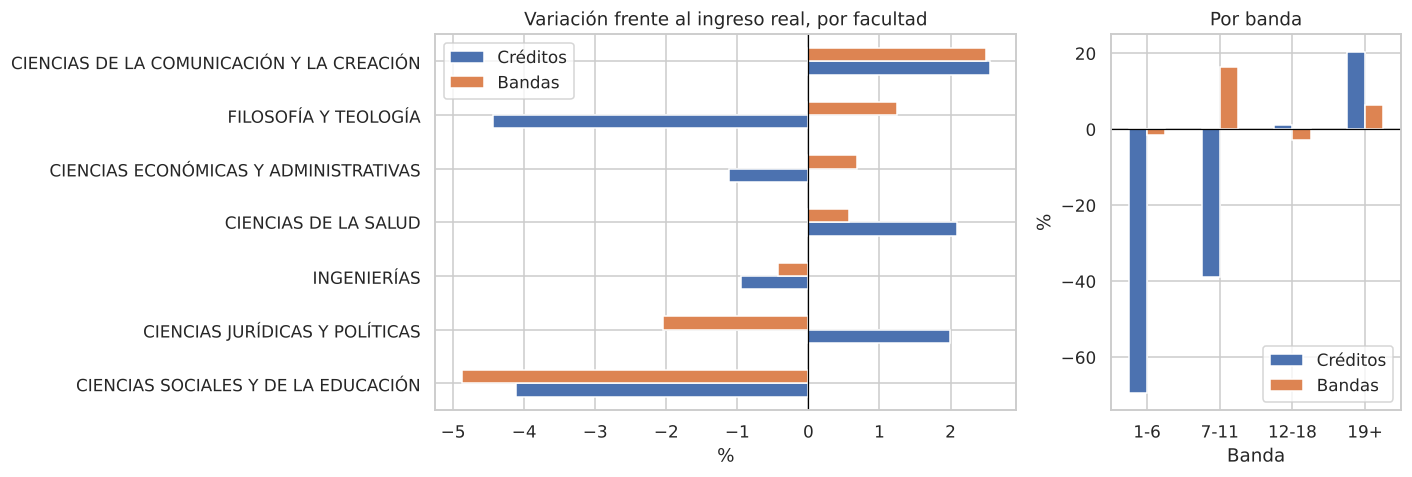

Por facultad (%)       
                                                  Créditos Bandas
FACULTAD                                                         
CIENCIAS DE LA COMUNICACIÓN Y LA CREACIÓN             2.56   2.50
CIENCIAS DE LA SALUD                                  2.09   0.57
CIENCIAS ECONÓMICAS Y ADMINISTRATIVAS                -1.11   0.68
CIENCIAS JURÍDICAS Y POLÍTICAS                        1.99  -2.05
CIENCIAS SOCIALES Y DE LA EDUCACIÓN                  -4.12  -4.88
FILOSOFÍA Y TEOLOGÍA                                 -4.44   1.24
INGENIERÍAS                                          -0.95  -0.43

In [9]:
param_eq = {"creditos": {"factor_tarifa": eq_cred}, "bandas": {"k_parcial": eq_band}}
comp_fac = pd.concat({METODOS[m]: sim.simular_por("FACULTAD", m, param_eq[m]).set_index("FACULTAD").BRECHA_PCT
                      for m in METODOS}, axis=1)
comp_banda = pd.concat({METODOS[m]: sim.simular_por("BANDA", m, param_eq[m]).set_index("BANDA").BRECHA_PCT
                        for m in METODOS}, axis=1).loc[["1-6", "7-11", "12-18", "19+"]]
guardar(comp_fac.round(3), "equilibrio_por_facultad.csv"); guardar(comp_banda.round(3), "equilibrio_por_banda.csv")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
comp_fac.sort_values("Bandas").plot.barh(ax=ax[0])
ax[0].axvline(0, c="black", lw=0.8); ax[0].set(title="Variación frente al ingreso real, por facultad", xlabel="%", ylabel="")
comp_banda.plot.bar(ax=ax[1], rot=0)
ax[1].axhline(0, c="black", lw=0.8); ax[1].set(title="Por banda", xlabel="Banda", ylabel="%")
plt.tight_layout(); plt.savefig(GRAFICAS / "03_equilibrio_por_facultad_y_banda.png", bbox_inches="tight"); plt.show()
pd.concat({"Por facultad (%)": comp_fac}, axis=1).round(2)

In [10]:
comp_banda.round(2)

,Créditos,Bandas
BANDA,,
1-6,-69.43,-1.60
7-11,-38.92,16.42
12-18,1.22,-2.69
19+,20.50,6.53


## 6. Simulación Monte Carlo

Se sortean 3.000 combinaciones de todas las palancas de cada método dentro de su rango válido y se calcula la brecha exacta de cada una.

In [11]:
def montecarlo(metodo, n=3000, semilla=2026):
    rng = np.random.default_rng(semilla)
    palancas = sim.metodo(metodo).palancas
    X = pd.DataFrame({p.nombre: rng.uniform(p.minimo, p.maximo, n) for p in palancas})
    X["brecha_mm"] = [sim.brecha(metodo, fila) for fila in X.to_dict("records")]
    return X

mc = {m: montecarlo(m) for m in METODOS}
resumen_mc = pd.DataFrame({METODOS[m]: {**mc[m].brecha_mm.describe().to_dict(),
                                         "pct_en_equilibrio(|brecha|<0,5)": (mc[m].brecha_mm.abs() < 0.5).mean() * 100}
                           for m in METODOS}).T
guardar(resumen_mc.round(4), "montecarlo_resumen.csv")
resumen_mc.round(2)

,count,mean,std,min,25%,50%,75%,max,"pct_en_equilibrio(|brecha|<0,5)"
Créditos,3000.0,21.57,120.18,-215.54,-75.39,29.33,113.54,312.16,0.17
Bandas,3000.0,16.29,48.44,-100.47,-23.44,16.61,53.75,121.11,0.83


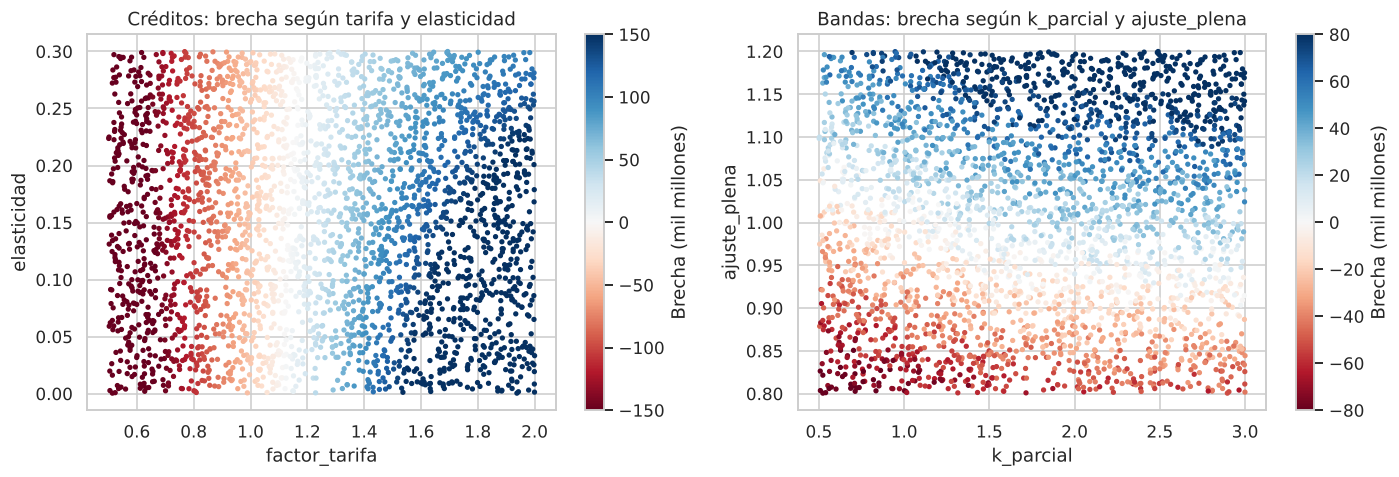

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
x = mc["creditos"]
sc = ax[0].scatter(x.factor_tarifa, x.elasticidad, c=x.brecha_mm, cmap="RdBu", vmin=-150, vmax=150, s=6)
ax[0].set(title="Créditos: brecha según tarifa y elasticidad", xlabel="factor_tarifa", ylabel="elasticidad")
plt.colorbar(sc, ax=ax[0], label="Brecha (mil millones)")
x = mc["bandas"]
sc = ax[1].scatter(x.k_parcial, x.ajuste_plena, c=x.brecha_mm, cmap="RdBu", vmin=-80, vmax=80, s=6)
ax[1].set(title="Bandas: brecha según k_parcial y ajuste_plena", xlabel="k_parcial", ylabel="ajuste_plena")
plt.colorbar(sc, ax=ax[1], label="Brecha (mil millones)")
plt.tight_layout(); plt.savefig(GRAFICAS / "04_montecarlo.png", bbox_inches="tight"); plt.show()

## 7. Metamodelo de *machine learning* (el que sirve `/predict`)

`backend/app/ml/train.py` simula 4.000 escenarios por método, compara cinco modelos con validación cruzada de 5 particiones y guarda el mejor como `Pipeline` con `joblib`. La API lo carga una sola vez con el patrón Singleton (`ModelStore`). Aquí se carga igual y se valida contra escenarios nuevos (los 3.000 de la sección 6, con otra semilla).

En créditos la brecha es un polinomio exacto de las palancas (tarifa × (1 − e·(tarifa − 1))), así que la regresión polinómica la reproduce sin error; en bandas el tope de las fracciones en 1 crea quiebres y gana la red neuronal.

In [13]:
artefactos = RAIZ / "backend/app/ml/artifacts"
comparacion = pd.read_csv(artefactos / "comparacion_modelos.csv", sep=";", decimal=",")
comparacion["metodo"] = comparacion.metodo.map(METODOS)
guardar(comparacion.round(6), "comparacion_modelos_ml.csv", index=False)
comparacion.round(4)

,modelo,r2_cv,mae_cv_mm,metodo
0,Polinómica grado 3 (Ridge),1.0000,0.0000,Créditos
1,Red neuronal (MLP),1.0000,0.3017,Créditos
2,Random Forest,0.9999,1.0361,Créditos
3,Gradient Boosting,0.9998,1.1186,Créditos
4,Regresión lineal,0.9669,17.0905,Créditos
5,Red neuronal (MLP),1.0000,0.1633,Bandas
6,Polinómica grado 3 (Ridge),0.9995,0.9448,Bandas
7,Gradient Boosting,0.9990,1.1737,Bandas
8,Random Forest,0.9975,1.7854,Bandas
9,Regresión lineal,0.9885,4.3277,Bandas


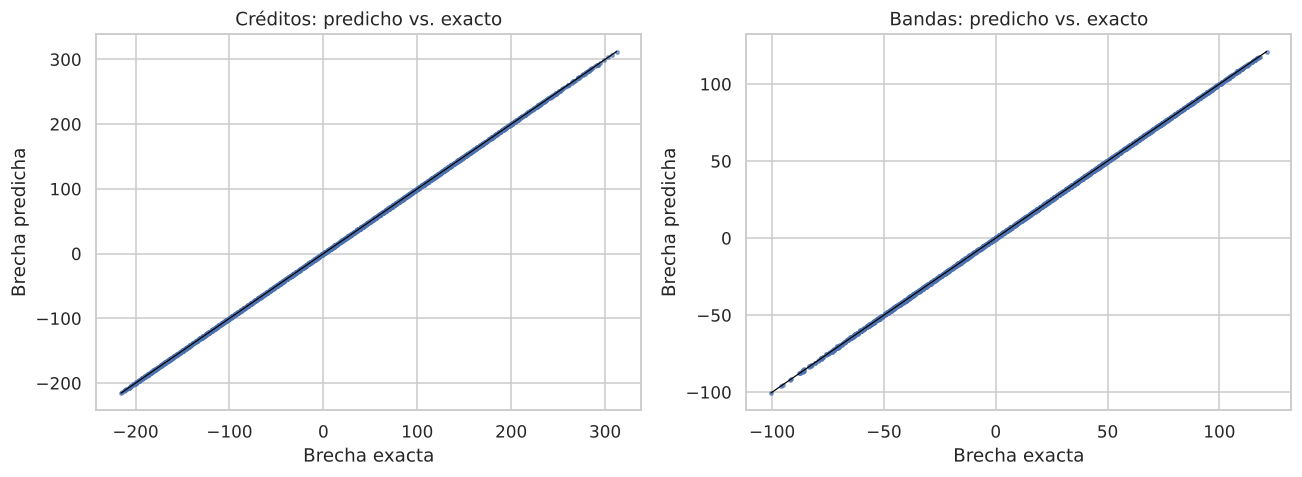

,Metodo,Modelo,R2,MAE_MM
0,Créditos,Polinómica grado 3 (Ridge),1.0,0.000
1,Bandas,Red neuronal (MLP),1.0,0.126


In [14]:
from sklearn.metrics import r2_score, mean_absolute_error
ModelStore.configurar(artefactos)
predictor = ModelPredictor(ModelStore.get(), ModelStore.metadata())

validacion = []
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for i, m in enumerate(METODOS):
    X = mc[m]
    pred = np.array([predictor.predecir(m, fila) for fila in X.drop(columns="brecha_mm").to_dict("records")])
    validacion.append({"Metodo": METODOS[m], "Modelo": predictor.metadata["modelos"][m]["modelo"],
                       "R2": r2_score(X.brecha_mm, pred), "MAE_MM": mean_absolute_error(X.brecha_mm, pred)})
    ax[i].scatter(X.brecha_mm, pred, s=5, alpha=0.6)
    lim = [X.brecha_mm.min(), X.brecha_mm.max()]; ax[i].plot(lim, lim, c="black", lw=0.8)
    ax[i].set(title=f"{METODOS[m]}: predicho vs. exacto", xlabel="Brecha exacta", ylabel="Brecha predicha")
plt.tight_layout(); plt.savefig(GRAFICAS / "05_metamodelo.png", bbox_inches="tight"); plt.show()
pd.DataFrame(validacion).round(4)

In [15]:
from scipy.optimize import brentq
from sklearn.inspection import permutation_importance

def equilibrio_ml(metodo, elasticidad):
    p = sim.metodo(metodo).palanca(PALANCA_PRINCIPAL[metodo])
    base = sim.metodo(metodo).parametros_actuales()
    f = lambda x: predictor.predecir(metodo, {**base, "elasticidad": elasticidad, p.nombre: x})
    return brentq(f, 1.0, 1.6)

frontera = pd.DataFrame([{"Metodo": METODOS[m], "elasticidad": e,
                          "exacto": sim.equilibrio(m, PALANCA_PRINCIPAL[m], {"elasticidad": e}),
                          "metamodelo": equilibrio_ml(m, e)}
                         for m in METODOS for e in [0, 0.1, 0.2, 0.3]])
frontera["error_abs"] = (frontera.metamodelo - frontera.exacto).abs()
guardar(frontera.round(5), "frontera_equilibrio_ml.csv", index=False)

Xb = mc["bandas"].drop(columns="brecha_mm")
imp = permutation_importance(predictor.modelos["bandas"], Xb, mc["bandas"].brecha_mm, n_repeats=5, random_state=0)
print("Importancia por permutación (bandas):")
print(pd.Series(imp.importances_mean, index=Xb.columns).sort_values(ascending=False).round(3).to_string())
frontera.round(4)

Importancia por permutación (bandas):
ajuste_plena    1.781
k_parcial       0.166
tarifa_extra    0.056
elasticidad     0.000


,Metodo,elasticidad,exacto,metamodelo,error_abs
0,Créditos,0.0,1.1149,1.1149,0.0000
1,Créditos,0.1,1.1295,1.1295,0.0000
2,Créditos,0.2,1.1492,1.1492,0.0000
3,Créditos,0.3,1.1777,1.1777,0.0000
4,Bandas,0.0,1.2784,1.2726,0.0058
5,Bandas,0.1,1.2860,1.2800,0.0059
6,Bandas,0.2,1.2931,1.2951,0.0019
7,Bandas,0.3,1.2999,1.3051,0.0053


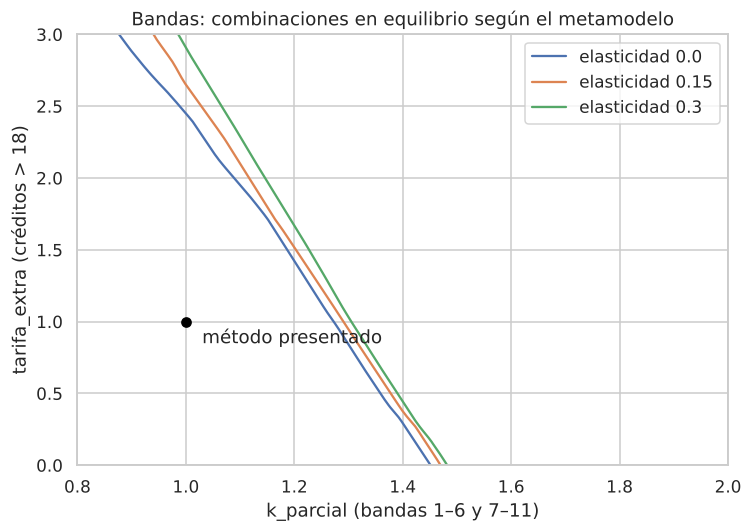

In [16]:
kk, tt = np.meshgrid(np.linspace(0.8, 2.0, 80), np.linspace(0.0, 3.0, 80))
fig, ax = plt.subplots(figsize=(7, 5))
for i, e in enumerate([0.0, 0.15, 0.3]):
    grilla = pd.DataFrame({"k_parcial": kk.ravel(), "ajuste_plena": 1.0, "tarifa_extra": tt.ravel(), "elasticidad": e})
    zz = predictor.modelos["bandas"].predict(grilla).reshape(kk.shape)
    ax.contour(kk, tt, zz, levels=[0], colors=[f"C{i}"])
    ax.plot([], [], c=f"C{i}", label=f"elasticidad {e}")
ax.scatter([1], [1], c="black", zorder=3); ax.annotate("método presentado", (1, 1), xytext=(1.03, 0.85))
ax.set(title="Bandas: combinaciones en equilibrio según el metamodelo",
       xlabel="k_parcial (bandas 1–6 y 7–11)", ylabel="tarifa_extra (créditos > 18)")
ax.legend(); plt.tight_layout(); plt.savefig(GRAFICAS / "06_frontera_bandas.png", bbox_inches="tight"); plt.show()

## 8. ¿Qué explica lo que pagan hoy los estudiantes?

Un *gradient boosting* predice la fracción de la matrícula plena que paga hoy cada estudiante (`VAL_PAGADO / M`). Sirve para ver el **precio implícito** actual por créditos y compararlo con los dos métodos en equilibrio.

In [17]:
if estudiantes is not None:
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import OneHotEncoder
    from sklearn.ensemble import HistGradientBoostingRegressor
    from sklearn.pipeline import make_pipeline
    from sklearn.model_selection import train_test_split

    datos = estudiantes[estudiantes.M > 0].copy()
    datos["FRACCION_PAGADA"] = (datos.VAL_PAGADO / datos.M).clip(upper=1.5)
    numericas = ["CREDITOS_INSCRITOS", "NIVEL_EST", "N_MATERIAS", "N_MATERIAS_REPITE", "PERIODO"]
    binarias = ["SUBSIDIO_EXTERNO", "ES_NUEVO", "REINTEGRO"]
    Xp = datos[numericas + binarias + ["FACULTAD"]].astype({c: int for c in binarias})
    yp = datos.FRACCION_PAGADA
    prep = ColumnTransformer([("fac", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["FACULTAD"])],
                             remainder="passthrough", verbose_feature_names_out=False)
    modelo_pago = make_pipeline(prep, HistGradientBoostingRegressor(max_iter=300, random_state=0))
    Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(Xp, yp, test_size=0.25, random_state=0)
    modelo_pago.fit(Xp_tr, yp_tr)
    pred_pago = modelo_pago.predict(Xp_te)
    print(f"R² prueba = {r2_score(yp_te, pred_pago):.3f} | MAE = {mean_absolute_error(yp_te, pred_pago):.3f} de M")
    muestra = Xp_te.sample(5000, random_state=0)
    imp_pago = permutation_importance(modelo_pago, muestra, yp_te.loc[muestra.index], n_repeats=5, random_state=0)
    display(pd.Series(imp_pago.importances_mean, index=Xp.columns).sort_values(ascending=False).round(4).to_frame("Importancia"))

R² prueba = 0.622 | MAE = 0.113 de M


,Importancia
CREDITOS_INSCRITOS,0.4380
N_MATERIAS,0.3836
FACULTAD,0.1021
PERIODO,0.0750
NIVEL_EST,0.0744
ES_NUEVO,0.0209
N_MATERIAS_REPITE,0.0174
SUBSIDIO_EXTERNO,0.0035
REINTEGRO,0.0008


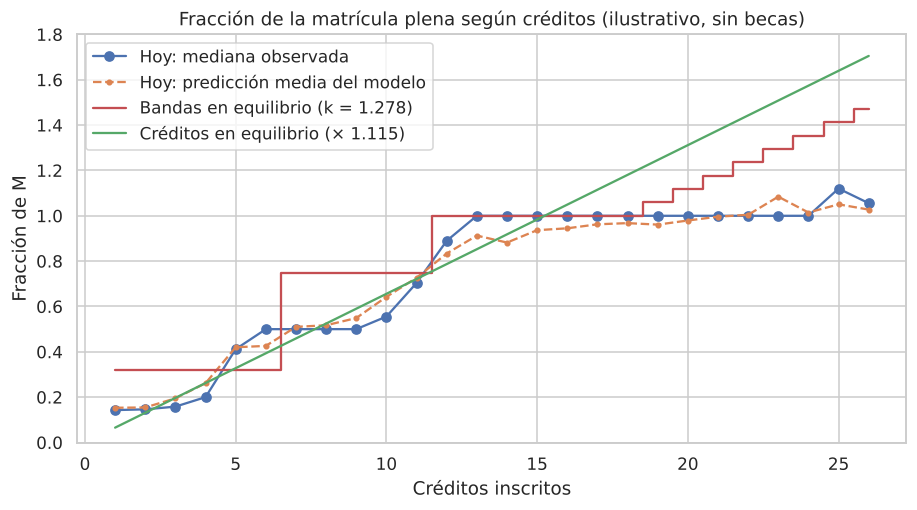

In [18]:
if estudiantes is not None:
    curva = (pd.DataFrame({"creditos": Xp_te.CREDITOS_INSCRITOS.clip(upper=26), "observado": yp_te, "modelo": pred_pago})
               .groupby("creditos").agg(observado=("observado", "median"), modelo=("modelo", "mean")))
    creditos_por_M = (estudiantes.M / estudiantes["T"]).median()     # créditos que "caben" en M
    c = np.arange(1, 27)
    bandas_eq = np.select([c <= 6, c <= 11, c <= 18], [fr.F1_equilibrio.mean(), fr.F2_equilibrio.mean(), 1.0],
                          default=1 + (c - 18) / creditos_por_M)
    creditos_eq = eq_cred * c / creditos_por_M
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    ax.plot(curva.index, curva.observado, marker="o", label="Hoy: mediana observada")
    ax.plot(curva.index, curva.modelo, ls="--", marker=".", label="Hoy: predicción media del modelo")
    ax.step(c, bandas_eq, where="mid", c="C3", label=f"Bandas en equilibrio (k = {eq_band:.3f})")
    ax.plot(c, creditos_eq, c="C2", label=f"Créditos en equilibrio (× {eq_cred:.3f})")
    ax.set(title="Fracción de la matrícula plena según créditos (ilustrativo, sin becas)",
           xlabel="Créditos inscritos", ylabel="Fracción de M", ylim=(0, 1.8))
    ax.legend(); plt.tight_layout(); plt.savefig(GRAFICAS / "07_precio_implicito.png", bbox_inches="tight"); plt.show()

## 9. ¿Los cortes 6 / 11 / 18 tienen sentido? (*clustering*)

K-Means agrupa a los estudiantes solo por créditos inscritos; los puntos medios entre centros son los cortes que «sugieren los datos».

In [19]:
if estudiantes is not None:
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score
    x_cred = estudiantes[["CREDITOS_INSCRITOS"]].to_numpy()
    muestra = x_cred[::10]
    filas = []
    for k in range(3, 7):
        km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(x_cred)
        centros = np.sort(km.cluster_centers_.ravel())
        filas.append({"k": k, "centros": np.round(centros, 1).tolist(),
                      "cortes_sugeridos": np.round((centros[1:] + centros[:-1]) / 2, 1).tolist(),
                      "silueta": silhouette_score(muestra, km.predict(muestra))})
    clusters = pd.DataFrame(filas)
    guardar(clusters, "kmeans_cortes.csv", index=False)
    display(clusters)

,k,centros,cortes_sugeridos,silueta
0,3,"[6.8, 13.7, 17.6]","[10.3, 15.7]",0.570938
1,4,"[6.2, 12.7, 16.2, 19.0]","[9.4, 14.4, 17.6]",0.574475
2,5,"[4.0, 9.1, 14.0, 16.9, 19.9]","[6.6, 11.6, 15.4, 18.4]",0.596927
3,6,"[4.6, 9.5, 13.3, 15.6, 17.4, 19.9]","[7.0, 11.4, 14.4, 16.5, 18.6]",0.632681


## 10. ¿El equilibrio se sostiene en el tiempo?

Validación temporal, como en ML: se calibra la palanca principal de cada método solo con 2021-1 a 2024-2 (**entrenamiento**) y se mide la brecha en 2025-1 a 2026-1 (**prueba**). También se calcula el valor que equilibraría cada periodo por separado.

In [20]:
todos = sim.periodos()
entrena = [p for p in todos if p <= 20242]; prueba = [p for p in todos if p > 20242]
temporal, por_periodo = [], []
for m in METODOS:
    palanca = PALANCA_PRINCIPAL[m]
    valor = sim.equilibrio(m, palanca, periodos=entrena)
    temporal.append({"Metodo": METODOS[m], "Palanca": palanca, "Valor_calibrado_2021_2024": valor,
                     "Valor_toda_la_base": sim.equilibrio(m, palanca),
                     "Brecha_pct_prueba_2025_2026": sim.simular(m, {palanca: valor}, prueba).brecha_pct})
    for p in todos:
        por_periodo.append({"Metodo": METODOS[m], "Periodo": p,
                            "Brecha_pct_presentado": sim.simular(m, periodos=[p]).brecha_pct,
                            "Brecha_pct_calibrado": sim.simular(m, {palanca: valor}, [p]).brecha_pct,
                            "Valor_equilibrio_periodo": sim.equilibrio(m, palanca, periodos=[p])})
temporal = pd.DataFrame(temporal); por_periodo = pd.DataFrame(por_periodo)
guardar(temporal.round(5), "validacion_temporal.csv", index=False)
guardar(por_periodo.round(5), "equilibrio_por_periodo.csv", index=False)
temporal.round(4)

,Metodo,Palanca,Valor_calibrado_2021_2024,Valor_toda_la_base,Brecha_pct_prueba_2025_2026
0,Créditos,factor_tarifa,1.1094,1.1149,-1.9193
1,Bandas,k_parcial,1.2140,1.2784,-1.9347


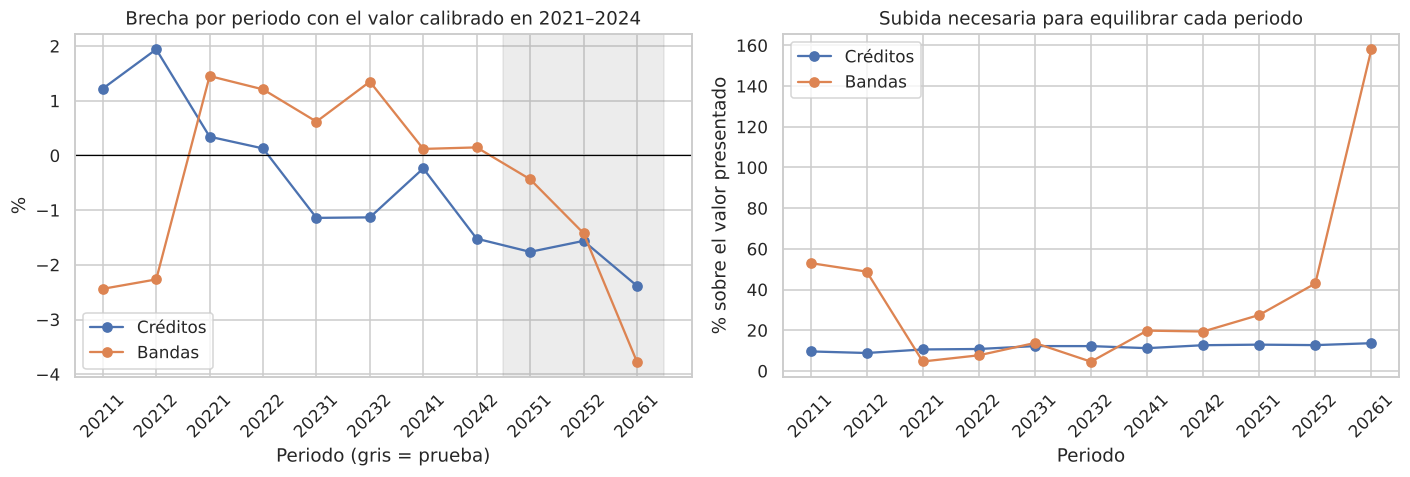

Metodo,Bandas,Créditos
Periodo,,
20211,1.530,1.096
20212,1.488,1.088
20221,1.047,1.106
20222,1.077,1.108
20231,1.138,1.122
20232,1.046,1.122
20241,1.198,1.112
20242,1.194,1.127
20251,1.275,1.129


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for i, m in enumerate(METODOS):
    d = por_periodo[por_periodo.Metodo == METODOS[m]]
    x = d.Periodo.astype(str)
    ax[0].plot(x, d.Brecha_pct_calibrado, marker="o", label=METODOS[m])
    ax[1].plot(x, (d.Valor_equilibrio_periodo - 1) * 100, marker="o", label=METODOS[m])
ax[0].axhline(0, c="black", lw=0.8); ax[0].axvspan(entrena.__len__() - 0.5, len(todos) - 0.5, color="grey", alpha=0.15)
ax[0].set(title="Brecha por periodo con el valor calibrado en 2021–2024", ylabel="%", xlabel="Periodo (gris = prueba)")
ax[1].set(title="Subida necesaria para equilibrar cada periodo", ylabel="% sobre el valor presentado", xlabel="Periodo")
for a in ax: a.tick_params(axis="x", rotation=45); a.legend()
plt.tight_layout(); plt.savefig(GRAFICAS / "08_validacion_temporal.png", bbox_inches="tight"); plt.show()
por_periodo.pivot(index="Periodo", columns="Metodo", values="Valor_equilibrio_periodo").round(3)

## 11. Conclusiones

1. **Punto de equilibrio de cada método.** Con los parámetros presentados, el cobro por créditos recauda 40,66 mil millones menos (−10,30 %) y el cobro por bandas, 8,42 menos (−2,13 %). Para igualar el ingreso real:
   - **Créditos:** subir la tarifa por crédito **11,49 %** (factor 1,1149). Es exactamente el cociente real / simulado, porque sin elasticidad el cobro es lineal en la tarifa.
   - **Bandas:** basta mover una palanca, cualquiera de estas: subir las fracciones de 1–6 y 7–11 un **27,8 %** (k = 1,278; quedan en promedio en 0,32 y 0,75 de M), subir la matrícula plena **2,2 %**, o cobrar el crédito por encima de 18 a **2,45 veces** T.
2. **A igual ingreso, reparten distinto.** En equilibrio, el cobro por créditos baja mucho lo que pagan quienes inscriben poco (−69 % en 1–6 y −39 % en 7–11) y lo compensa con quienes inscriben 19 o más (+20 %). El de bandas se parece más a lo que se cobra hoy: −2 % en 1–6, +16 % en 7–11 y +7 % en 19+. Por facultad, los dos métodos quedan entre −5 % y +2,6 %, pero no siempre en la misma dirección (por ejemplo, Filosofía y Teología: −4,4 % con créditos y +1,2 % con bandas).
3. **Reacción de los estudiantes (supuesto).** Si los estudiantes inscriben menos créditos cuando sube el precio, el método por créditos es más sensible: con elasticidad 0,3 la subida necesaria pasa de 11,5 % a 17,8 %, mientras que en bandas k solo pasa de 1,278 a 1,300.
4. **Machine learning.** El metamodelo que sirve `/predict` reproduce el simulador con R² ≈ 1. En créditos la regresión polinómica es exacta y en bandas la red neuronal tiene un error medio de 0,13 mil millones. Con el metamodelo se obtiene el mismo equilibrio que con el cálculo exacto (diferencia ≤ 0,006 en k). La regresión del pago actual muestra que los créditos y el número de materias son lo que más explica cuánto paga hoy cada estudiante. K-Means con 5 grupos sugiere cortes en ≈ 6,6, 11,6 y 18,4 créditos, prácticamente los mismos de las bandas.
5. **El equilibrio cambia con el tiempo.** Si cada método se calibra con 2021–2024, en 2025–2026 los dos quedan ≈ 1,9 % por debajo del ingreso real. El factor de créditos que equilibra cada periodo es estable (entre 1,09 y 1,14). El k de bandas varía mucho (entre 1,05 y 2,58), porque actúa sobre solo el 17 % de los estudiantes. En la práctica, cualquiera de los dos parámetros tendría que recalibrarse cada año. Si se usan bandas, conviene ajustar la matrícula plena en vez de k.

**Limitaciones.** El modelo base es estático: solo el escenario de elasticidad mueve créditos, y como supuesto. Las becas se miden como en cada análisis previo: frente a M en el de créditos y frente a lo que hoy paga la misma facultad y banda en el de bandas.